# PDFT Calculation for H$_2^+$ (one electron)

In [1]:
import numpy as np
from pyscf import dft, scf
from f4b import pdft, fgto
from pyscf.dft import numint
import matplotlib.pyplot as plt

# function to get density in grid given density matrix and basis functions
def D2n(D, *phis):
    ngrid = len(phis)
    n = 0.
    for phi in phis:
        n += np.einsum("pu,pv,uv->p", phi, phi, D, optimize=True)
    n /= ngrid
    return n

---
## Set up fragments and do reference calculation

With one electron there is no Hartree or exchange-correlation interaction to approximate, so with a GGA the self-interaction error of PBE
(several mEh for H$_2^+$) would dominate the comparison. `f4b` detects that the whole system has one electron and switches to an **exact one-electron mode**:
the fragments are solved with Hartree-Fock (exact for one electron), the partition potential update uses only the kinetic-energy functional
(von Weizsäcker, exact for one electron) and the external potential, and the energy is $T_s^{vW} + E_{ext} + E_{nn}$. The reference is therefore
**UHF**, not PBE. Pass `one_electron=False` to go back to the PBE description.

Each fragment holds half an electron: `{'charge': {0: 0.5, 1: 0.5}}` is an equal ensemble of no electrons and one H atom. A large basis is needed (cc-pVQZ here)
because the exact partition potential is very structured.

In [2]:
sep = 2.0
mol = fgto.M(atom=f"""
    H {-0.5*sep} 0 0
    H {+0.5*sep} 0 0
""", unit='bohr', basis='cc-pvqz', charge=1, spin=1,
    fragments={0: [0], 1: [1]},
    ensembles={'charge': {0: 0.5, 1: 0.5}})         # each fragment: half an electron
print(mol)

my_dft = scf.UHF(mol.mol)                           # exact for one electron
my_dft.kernel()
Eref, Dref = my_dft.e_tot, my_dft.make_rdm1()       # Dref = (alpha, beta) density matrices
print(f"{Eref = :.8f}")

grids = dft.gen_grid.Grids(mol.mol)
grids.level = 7
grids.build()
coords = grids.coords
w = grids.weights
phi = dft.numint.eval_ao(mol.mol, coords, deriv=0)
nref = D2n(Dref[0] + Dref[1], phi)                  # spin-summed reference density

FragMole:
  Fragment 0: atoms=(0,) Z=1 members=[(0,0;w=0.5,flip=0), (1,0;w=0.5,flip=0)]
  Fragment 1: atoms=(1,) Z=1 members=[(0,0;w=0.5,flip=0), (1,0;w=0.5,flip=0)]
Eref = -0.60252058


---
## Do PDFT Calculations

### Functional Method (accurate and fast in this mode)

In [3]:
mf2 = pdft.RKS(mol, method='functional-T', accel='diis', maxiter=10, grid_level=6)
mf2.kernel()
E_mf2, Df_mf2 = mf2.e_tot, mf2.make_rdm1()
nf_mf2 = D2n(Df_mf2[0]+Df_mf2[1], phi)

dE_mf2 = abs(Eref-E_mf2)
L1_mf2 = np.sum(np.abs(nf_mf2-nref)*w)
Nf_mf2 = np.sum(nf_mf2*w)
print(f"Energy difference (Ha): {dE_mf2:.3e}, Density error: {L1_mf2:.3e}, integrated density: {Nf_mf2:.6f}")

P-DFT method=functional xc=PBE fxc=PBE nao=60 grid=72080


  it    1  Ef =    -0.4999460598  dEf =         nan  |dVp| = 1.552e+00


  it    2  Ef =    -0.4835937597  dEf =   1.635e-02  |dVp| = 8.097e-01


  it    3  Ef =    -0.4507842057  dEf =   3.281e-02  |dVp| = 1.782e-01


  it    4  Ef =    -0.4473579571  dEf =   3.426e-03  |dVp| = 1.276e-01


  it    5  Ef =    -0.4471430335  dEf =   2.149e-04  |dVp| = 1.061e-01


... (3 outputs left out)

  it    9  Ef =    -0.4467054026  dEf =  -4.176e-05  |dVp| = 8.160e-02


  it   10  Ef =    -0.4469224515  dEf =  -2.170e-04  |dVp| = 1.334e-01


/home/ulises/Documents/Research/PDFT_package_dev/f4b/f4b/pdft.py:425: UserWarning: P-DFT did not converge in 10 iterations; using the best iterate
  warnings.warn(f"P-DFT did not converge in {self.maxiter} iterations; using the best iterate")


Energy difference (Ha): 4.289e-06, Density error: 2.021e-03, integrated density: 1.000000


Ten iterations are enough: the partition potential is accurate to ~1e-5 Eh in the energy after about 9 iterations. More iterations with `accel='diis'` can start to wander
once the residual is down to ~0.1 (`f4b` always returns the best iterate, and stops by itself if the iteration diverges).

The `inversion` and `reference` methods also work in this mode but converge slowly (the inversion is limited by its regularization, `inv_reg`), so
`functional-T` is the recommended choice for one-electron systems.

---
## Plot densities and partition potential

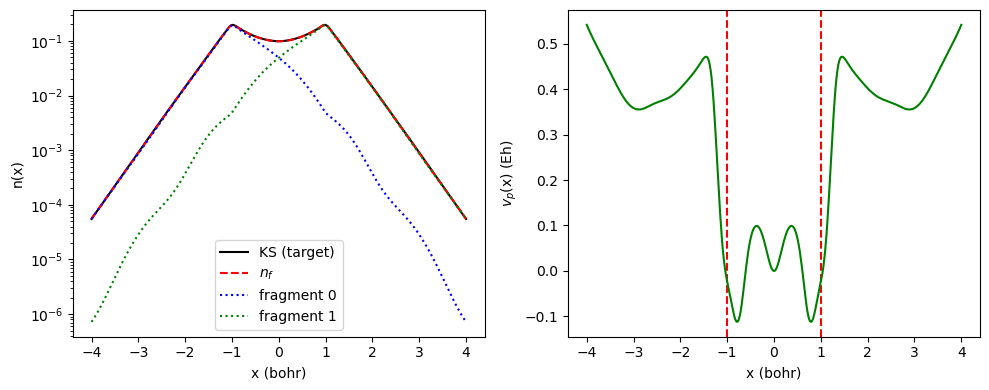

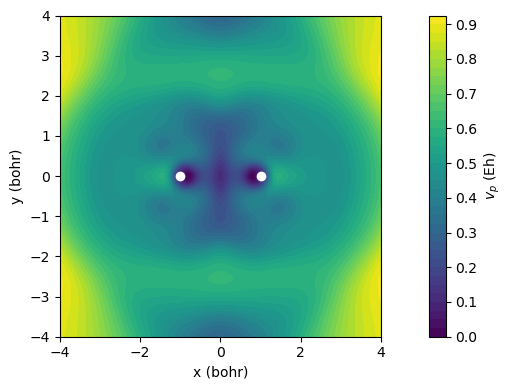

In [4]:
# # 1D plot along molecular axis
x = np.linspace(-4, 4, 400)
line = np.column_stack([x, np.zeros_like(x), np.zeros_like(x)])
n_f = mf2.eval_density(line)                    # promolecular density
n_0 = mf2.eval_density(line, frag=0)            # fragment densities
n_1 = mf2.eval_density(line, frag=1)
vp  = mf2.eval_Vp(line)
n_ks = numint.eval_rho(mol.mol, numint.eval_ao(mol.mol, line), Dref[0] + Dref[1]) # target (plain KS) density on the same points
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].semilogy(x, n_ks, 'k-', label='KS (target)')
ax[0].semilogy(x, n_f, 'r--', label='$n_f$')
ax[0].semilogy(x, n_0, 'b:', label='fragment 0')
ax[0].semilogy(x, n_1, 'g:', label='fragment 1')
for Ri in mol.mol.atom_coords(): ax[1].axvline(x=Ri[0], color='r', linestyle='dashed')
ax[0].set_xlabel('x (bohr)'); ax[0].set_ylabel('n(x)'); ax[0].legend()
ax[1].plot(x, vp - vp[len(x) // 2], 'g-')      # Vp is defined up to a constant: fix a reference point
ax[1].set_xlabel('x (bohr)'); ax[1].set_ylabel('$v_p$(x) (Eh)')
fig.tight_layout()
plt.show()

# 2D map of Vp in the xy plane (z = 0)
x = np.linspace(-4, 4, 160); yy = np.linspace(-4, 4, 160)
X, Y = np.meshgrid(x, yy)
pts = np.column_stack([X.ravel(), Y.ravel(), np.zeros(X.size)])
V = mf2.eval_Vp(pts).reshape(X.shape)
fig, ax = plt.subplots(figsize=(10, 4))
c = ax.contourf(X, Y, V - V.min(), 40, cmap='viridis'); fig.colorbar(c, label='$v_p$ (Eh)')
for Ri in mol.mol.atom_coords():  ax.plot(Ri[0], Ri[1], 'wo')
ax.set_xlabel('x (bohr)'); ax.set_ylabel('y (bohr)'); ax.set_aspect('equal')
fig.tight_layout()
plt.show()